In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,Flatten,Dense
from sklearn.metrics import classification_report, confusion_matrix


In [4]:
train = pd.read_csv("Downloads/Fashion MNIST-20221031T093245Z-001/Fashion MNIST/fashion-mnist_train.csv/fashion-mnist_train.csv")
test = pd.read_csv("Downloads/Fashion MNIST-20221031T093245Z-001/Fashion MNIST/fashion-mnist_test.csv/fashion-mnist_test.csv")

print("data loaded Successfully ")

data loaded Successfully 


In [5]:
x_train = train.iloc[: , 1:].values.reshape(-1,28,28,1) / 255.0
y_train = train.iloc[: , 0].values

x_test = test.iloc[: , 1:].values.reshape(-1,28,28,1) / 255.0
y_test = test.iloc[: , 0].values

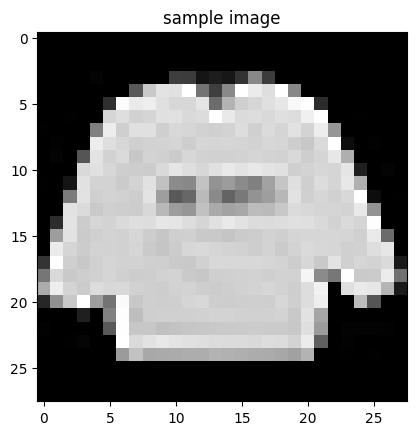

In [6]:
plt.imshow(x_train[0].reshape(28,28,1), cmap='gray')
plt.title("sample image")
plt.show()

In [7]:
model = Sequential(
    [  Conv2D(32, (3,3), activation='relu', input_shape = (28,28,1 )),
       MaxPool2D(2,2),
       Conv2D(64, (3,3), activation='relu'),
        MaxPool2D(2,2),
       Flatten(),
       Dense(128 , activation='relu'),
       Dense(10, activation= 'softmax')
          
    ]
)

model.compile(
       optimizer = 'adam',
       loss='sparse_categorical_crossentropy',
       metrics = ['accuracy']
    
)

model.summary()

C:\Users\sujal\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train,y_train,
    epochs=5,
    batch_size= 64,
    validation_split=0.2
    
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8074 - loss: 0.5283 - val_accuracy: 0.8624 - val_loss: 0.3891
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8758 - loss: 0.3463 - val_accuracy: 0.8838 - val_loss: 0.3332
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8906 - loss: 0.2986 - val_accuracy: 0.8764 - val_loss: 0.3329
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9020 - loss: 0.2664 - val_accuracy: 0.9018 - val_loss: 0.2710
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9109 - loss: 0.2406 - val_accuracy: 0.8995 - val_loss: 0.2688


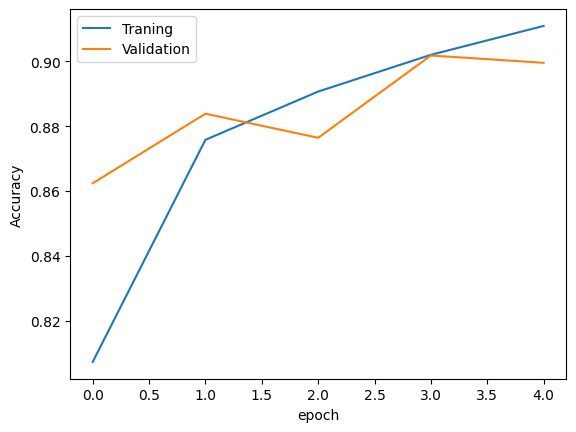

In [9]:
plt.plot(history.history['accuracy'], label="Traning")
plt.plot(history.history['val_accuracy'], label= "Validation")
plt.xlabel("epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [10]:
#Evaluation model 
loss, accuracy = model.evaluate(x_test,y_test)
print("Accuracy:", round(accuracy * 100 ,2), "%")
print("loss:", round(loss,4))

predictions = model.predict(x_test)
y_pred= np.argmax(predictions, axis=1)

print("Acutal:", y_test[0]) 
print("pred:", y_pred[0])



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9061 - loss: 0.2565
Accuracy: 90.61 %
loss: 0.2565
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Acutal: 0
pred: 0


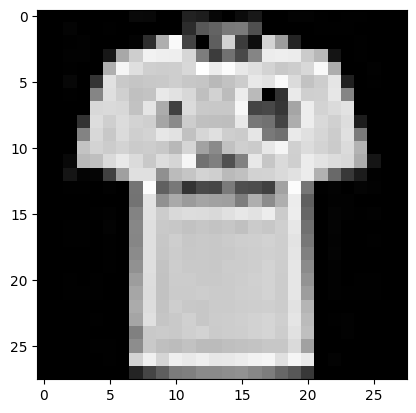

In [11]:
import matplotlib.pyplot as plt 
plt.imshow(x_test[0].reshape(28,28), cmap= 'gray')
plt.show()

In [12]:
print(history.history['accuracy'])
print(history.history['val_accuracy'])

[0.8074166774749756, 0.8757916688919067, 0.8906458616256714, 0.9019583463668823, 0.910854160785675]
[0.862416684627533, 0.8838333487510681, 0.8764166831970215, 0.9017500281333923, 0.8995000123977661]
